# GIN and GCN: Predicting the Adjacency Spectral Radius

A supervised comparison of **GIN** (Graph Isomorphism Network) and **GCN** (Graph Convolutional Network) on the target $\rho(A(G))$, with constant node features $x_v=1$.

This notebook documents the main width-64 comparison (experiment **87a8**) and a wider-GCN control with approximately matched parameter count (experiment **26d0**), both on the same subset of **50,000 graphs** from the CuriosAI dataset. See the [project README](README.md) and [full thesis](thesis.pdf) for context.

**Reading guide.** Sections 1–4 prepare data, models, and functions; Section 5 distinguishes new training from optional reloading; Section 6 plots the main comparison; Section 7 records the original results.

**View the saved results:** read the existing outputs without running any cells. These outputs come from the original experiments and were not regenerated when preparing this repository.

**Run new training:** execute Sections 1–4, then 5.1 and optionally 5.2. Skip 5.3 when plotting the histories just produced, and continue with Section 6. Sections 5.1 and 5.2 start new training jobs. Section 7 is a static record and is not automatically updated after training.

**Reload the original main models:** with the original history archive and all six checkpoints beside the notebook, run Sections 1 and 3, then 5.3 and the plotting cells in Section 6. Binary histories and weights are separate files, not embedded in this notebook.

## 1. Environment, imports, and reproducibility

Before opening the notebook, install the dependencies with `python -m pip install -r requirements.txt`. Run Jupyter from the repository root, with `gin_vs_gcn.ipynb` beside `dataset/`. See [dataset/README.md](dataset/README.md) for the expected graph files.

`set_seed` initializes the Python and PyTorch random generators, including CUDA generators. It does not enforce deterministic CUDA algorithms: identical seeds do not guarantee bit-for-bit identical results across platforms. The original experiment recorded **Python 3.12**, **PyTorch Geometric 2.6.1**, **Matplotlib 3.9.2**, and an **NVIDIA RTX 6000 Ada Generation** GPU. The original PyTorch and scikit-learn versions were not recorded in the supplied setup output.

The `to_undirected` import is used to represent both directions of every undirected edge.


In [ ]:
# Install dependencies first: python -m pip install -r requirements.txt

import json
import random
import uuid
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, GCNConv, global_mean_pool


# The dataset stores each undirected edge only once, whereas
# PyTorch Geometric interprets edge_index as directed.
# We import to_undirected to explicitly add the reverse edges.
from torch_geometric.utils import to_undirected

from sklearn.model_selection import train_test_split


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(42)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device used: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

## 2. Data and reference baseline

### 2.1. Loading and fixed 80/10/10 split

The following cell reads the JSON files from `dataset/` relative to the repository root, sorting them by the first number in the filename. Each item in `graph_list` becomes a `Data` object: `x` contains only ones, one for each node; `edge_index` contains the edges in both directions; and `y` uses **`graph_features[6]`**, identified by the loader as the adjacency spectral radius. The other invariants are not inputs to the network.

After loading all **313,597 graphs** reported in the output, the code shuffles the list with a local generator initialized to 42 and selects the first **50,000**. Two calls to `train_test_split` with `random_state=42` produce **40,000 training, 5,000 validation, and 5,000 test graphs**. All `DataLoader` instances use a **batch size of 32**; only the training loader shuffles the graphs.

The split is unique and shared by all architectures and seeds: the three runs do not use three different splits. `min(50000, len(dataset))` caps the subset at the available graph count. Using fewer or different source graphs changes the sample and results; preserve the original filenames, JSON contents, and graph order to reproduce the documented split. The loader neither checks for the absence of isomorphisms across splits nor recomputes the eigenvalues; it assumes that these conditions have already been verified in the dataset, as they were in our case.

In [ ]:
from pathlib import Path
import re
from IPython.display import display

dataset_dir = Path("dataset")

json_files = sorted(
    dataset_dir.glob("*.json"),
    key=lambda p: int(re.search(r'\d+', p.stem).group())
)

if not json_files:
    raise FileNotFoundError(
        "No graph JSON files found in dataset/. "
        "Add the original files as described in dataset/README.md "
        "and start Jupyter from the repository root."
    )

dataset = []

total_display = display("Caricati finora: 0 grafi.", display_id=True)
current_display = display("Caricamento non ancora iniziato.", display_id=True)

for filename in json_files:

    current_display.update(f"Caricamento in corso di {filename.name}...")

    with open(filename, 'r') as f:
        data = json.load(f)

        for graph_dict in data['graph_list']:
            num_nodes = len(graph_dict['nodes'])
            edges = graph_dict['edges']

            if len(edges) > 0:
                edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
                # In the JSON files, each edge of an undirected graph appears
                # only once. PyTorch Geometric interprets edge_index as directed,
                # so we explicitly add the reverse edge to ensure correct message
                # passing on the undirected graph.
                edge_index = to_undirected(edge_index, num_nodes=num_nodes)

            else:
                edge_index = torch.empty((2, 0), dtype=torch.long)

            # target (spectral radius of A(G), index 6)
            features = graph_dict['graph_features']
            y = torch.tensor([[features[6]]], dtype=torch.float)

            # dummy feature for each node
            x = torch.ones((num_nodes, 1), dtype=torch.float)

            graph = Data(x=x, edge_index=edge_index, y=y)
            dataset.append(graph)

    total_display.update(f"Caricati finora: {len(dataset)} grafi.")

current_display.update("Caricamento completato.")


# subset di 50.000 grafi
subset_size = min(50000, len(dataset))

rng = random.Random(42)
rng.shuffle(dataset)

dataset_ridotto = dataset[:subset_size]


train_data, temp_data = train_test_split(
    dataset_ridotto,
    test_size=0.2,
    random_state=42
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.5,
    random_state=42
)


train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(f"Dataset preparato: {subset_size} grafi totali utilizzati.")
print(
    f"Train: {len(train_data)} | "
    f"Validation: {len(val_data)} | "
    f"Test: {len(test_data)}"
)

'Caricati finora: 313597 grafi.'

'Caricamento completato.'

Dataset preparato: 50000 grafi totali utilizzati.
Train: 40000 | Validation: 5000 | Test: 5000


### 2.2. Constant baseline estimated on the training set

The constant prediction is the **mean of the training targets only**, i.e., the minimizer of the training MSE over all constant predictors. The same constant is then evaluated on the training, validation, and test sets, without using the graph structure.

In the saved outputs, the prediction is **13.3180** and the test MSE is **113.7849**. The baseline does not have three random initializations, so no standard deviation across seeds is assigned to it.

In [ ]:
baseline_value = sum(
    graph.y.item() for graph in train_data
) / len(train_data)


def constant_baseline_mse(data, prediction):
    return sum(
        (graph.y.item() - prediction) ** 2
        for graph in data
    ) / len(data)


baseline_train_mse = constant_baseline_mse(
    train_data,
    baseline_value
)

baseline_val_mse = constant_baseline_mse(
    val_data,
    baseline_value
)

baseline_test_mse = constant_baseline_mse(
    test_data,
    baseline_value
)


print(f"Baseline constant prediction: {baseline_value:.4f}")
print(f"Baseline Train MSE:      {baseline_train_mse:.4f}")
print(f"Baseline Validation MSE: {baseline_val_mse:.4f}")
print(f"Baseline Test MSE:       {baseline_test_mse:.4f}")

Baseline constant prediction: 13.3180
Baseline Train MSE:      113.7498
Baseline Validation MSE: 114.2263
Baseline Test MSE:       113.7849


## 3. Architectures and number of parameters

The following cell defines `GINModel`, `GCNModel`, and `count_trainable_parameters`. Both models have **three message-passing layers**, **global mean pooling**, and a head consisting of a `ReLU` followed by **a single affine layer** that produces the scalar output. ReLU activations follow the first two convolutions; after the third convolution, pooling is performed first, followed by the head's ReLU. Each GIN convolution also contains an MLP: `Linear → ReLU → Linear`.

The main comparison matches architectural characteristics, using three hidden layers with 64 nodes each. This, however, creates an asymmetry in the number of parameters: **GIN has 20,993 parameters** and **GCN has 8,513**. Therefore, the control experiment in Section 5.2 uses the same GCN class with width 101, which is sufficient to bring it to **20,908 parameters**. It still has 85 fewer parameters than GIN, but this difference is negligible (0.405%).

The `GINConv(...)` calls do not specify `train_eps=True`. In version 2.6.1, the defaults are `eps=0.0` and `train_eps=False`: this is therefore a **GIN with ε fixed at zero**, not learned. The `GCNConv` layers use the default symmetric normalization, self-loops, and biases. Detailed references: [GINConv 2.6.1](https://pytorch-geometric.readthedocs.io/en/2.6.1/generated/torch_geometric.nn.conv.GINConv.html) and [GCNConv 2.6.1](https://pytorch-geometric.readthedocs.io/en/2.6.1/generated/torch_geometric.nn.conv.GCNConv.html).

Message summation **within GIN** should not be confused with the **global readout**, which is always a mean here. There is no variant using `global_add_pool` in the following cell. The combination of fixed ε, finite MLPs, and mean readout does not automatically satisfy all assumptions of the equivalence theorem with 1-WL.

In [ ]:
# --- GIN ---
class GINModel(torch.nn.Module):
    def __init__(self, hidden_channels):
        super(GINModel, self).__init__()
        self.conv1 = GINConv(nn.Sequential(
            nn.Linear(1, hidden_channels), nn.ReLU(), nn.Linear(hidden_channels, hidden_channels)
        ))
        self.conv2 = GINConv(nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels), nn.ReLU(), nn.Linear(hidden_channels, hidden_channels)
        ))
        self.conv3 = GINConv(nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels), nn.ReLU(), nn.Linear(hidden_channels, hidden_channels)
        ))
        self.lin = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = self.conv3(x, edge_index)
        x = global_mean_pool(x, batch)
        return self.lin(F.relu(x))


# --- GCN ---
class GCNModel(torch.nn.Module):
    def __init__(self, hidden_channels):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(1, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.conv3 = GCNConv(hidden_channels, hidden_channels)
        self.lin = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = self.conv3(x, edge_index)
        x = global_mean_pool(x, batch)
        return self.lin(F.relu(x))


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 4. Training, validation, and checkpoint selection

`train_model` runs one epoch with MSE and weight updates; `evaluate_model` computes the MSE without gradients. In both functions, minibatch losses are weighted by `data.num_graphs`, so the final average is computed per graph, even when the last batch is smaller.

`run_experiment` uses **Adam**, selects the checkpoint with the **strictly lowest validation MSE**, and stops training after `patience` consecutive epochs without improvement, within `max_epochs`. In the saved runs: **learning rate $10^{-3}$, maximum of 500 epochs, patience 50**. Once training ends, it reloads the best checkpoint and evaluates the test set once per run.
The function returns the complete training history, the complete validation history, and the final test MSE.

In [ ]:
def train_model(model, loader, optimizer):
    model.train()
    total_loss = 0

    for data in loader:
        data = data.to(device)

        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)
        loss = F.mse_loss(out, data.y.view_as(out))
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * data.num_graphs

    return total_loss / len(loader.dataset)


def evaluate_model(model, loader):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for data in loader:
            data = data.to(device)

            out = model(data.x, data.edge_index, data.batch)
            loss = F.mse_loss(out, data.y.view_as(out))

            total_loss += loss.item() * data.num_graphs

    return total_loss / len(loader.dataset)


def run_experiment(
    model_name,
    model,
    train_loader,
    val_loader,
    test_loader,
    max_epochs=500,
    patience=50,
    lr=0.001
):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    print(f"\n--- Starting training: {model_name} ---")

    history_train = []
    history_val = []

    best_val_loss = float('inf')
    best_epoch = 0
    epochs_without_improvement = 0

    best_model_path = f"best_{model_name.lower()}.pth"

    for epoch in range(1, max_epochs + 1):

        train_loss = train_model(model, train_loader, optimizer)
        val_loss = evaluate_model(model, val_loader)

        history_train.append(train_loss)
        history_val.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(model.state_dict(), best_model_path)

        else:
            epochs_without_improvement += 1

        if epoch % 10 == 0:
            print(
                f'Epoch: {epoch:03d} | '
                f'Train Loss: {train_loss:.4f} | '
                f'Validation Loss: {val_loss:.4f}'
            )

        if epochs_without_improvement >= patience:
            print(
                f"Early stopping at epoch {epoch}: "
                f"no improvement in validation loss "
                f"for the last {patience} epochs."
            )
            break

    model.load_state_dict(
        torch.load(
            best_model_path,
            map_location=device,
            weights_only=True
        )
    )

    test_loss = evaluate_model(model, test_loader)

    print(f"--- Training {model_name} completed ---")
    print(
        f"Best model: epoch {best_epoch}, "
        f"Validation Loss = {best_val_loss:.4f}"
    )
    print(f"Checkpoint: {best_model_path}")
    print(f"Final Test Loss: {test_loss:.4f}")

    return history_train, history_val, test_loss

## 5. Experiments and reloading

### 5.1. Main comparison: GIN and GCN, width 64

The training cell below performs six runs: GIN and GCN with seeds **42, 43, and 44**, always on the same split from Section 2. It resets the seed before initializing each model and before training. It therefore compares architectures with equal depth and width, **not** with equal numbers of parameters.

For each model, it saves the best checkpoint; at the end, it prints the mean and **sample standard deviation** (`torch.std`, correction 1) of the three test MSEs and saves the histories, configuration, and baseline. The documented run has ID **87a8** and archive `training_history_h64_lr1e-3_p50_87a8.pt`. The dispersion measures variability across seeds on the same split, not uncertainty caused by different graph samples.

**This cell starts new training runs.** To reuse the existing outputs, skip it and read the saved outputs. Section 5.3 is available only when the original binary artifacts are present. Before starting new training, run Sections 1–4, including the baseline in Section 2.2, which is required for the final save.


In [ ]:
hidden_channels = 64
learning_rate = 1e-3
max_epochs = 500
patience = 50

# Compact form of learning rate for file names. ex.: 0.001 -> "1e-3"
lr_tag = f"{learning_rate:.0e}".replace("e-0", "e-").replace("e+0", "e+")

# Each 4-characters ID corresponds to a run.
# Re-running generates a new ID to not overwrite past experiments.

experiment_id = uuid.uuid4().hex[:4]

print(f"Experiment ID: {experiment_id}")
print(
    f"Configuration: h={hidden_channels}, "
    f"lr={learning_rate}, max_epochs={max_epochs}, "
    f"patience={patience}"
)

seeds = [42, 43, 44]

gin_runs = []
gcn_runs = []

for seed in seeds:

    print(f"\n==================== SEED {seed} ====================")

    # --- GIN ---

    set_seed(seed)
    model_gin = GINModel(hidden_channels=hidden_channels).to(device)

    set_seed(seed)

    gin_name = (
    f"GIN_h{hidden_channels}_lr{lr_tag}_p{patience}_"
    f"s{seed}_{experiment_id}"
    )

    gin_train_loss, gin_val_loss, gin_test_loss = run_experiment(
        gin_name,
        model_gin,
        train_loader,
        val_loader,
        test_loader,
        max_epochs=max_epochs,
        patience=patience,
        lr=learning_rate
    )

    gin_runs.append({
        'seed': seed,
        'train_loss': gin_train_loss,
        'val_loss': gin_val_loss,
        'test_loss': gin_test_loss,
    })


    # --- GCN ---

    set_seed(seed)
    model_gcn = GCNModel(hidden_channels=hidden_channels).to(device)

    set_seed(seed)

    gcn_name = (
    f"GCN_h{hidden_channels}_lr{lr_tag}_p{patience}_"
    f"s{seed}_{experiment_id}"
    )

    gcn_train_loss, gcn_val_loss, gcn_test_loss = run_experiment(
        gcn_name,
        model_gcn,
        train_loader,
        val_loader,
        test_loader,
        max_epochs=max_epochs,
        patience=patience,
        lr=learning_rate
    )

    gcn_runs.append({
        'seed': seed,
        'train_loss': gcn_train_loss,
        'val_loss': gcn_val_loss,
        'test_loss': gcn_test_loss,
    })


print("\nTrainable parameters:")
print(f"GIN: {count_trainable_parameters(model_gin)}")
print(f"GCN: {count_trainable_parameters(model_gcn)}")


gin_test_losses = torch.tensor([run['test_loss'] for run in gin_runs])
gcn_test_losses = torch.tensor([run['test_loss'] for run in gcn_runs])

print("\nTest MSE over 3 runs:")
print(
    f"GIN: {gin_test_losses.mean().item():.4f} "
    f"± {gin_test_losses.std().item():.4f}"
)
print(
    f"GCN: {gcn_test_losses.mean().item():.4f} "
    f"± {gcn_test_losses.std().item():.4f}"
)



history_data = {
    'experiment_id': experiment_id,
    'config': {
        'hidden_channels': hidden_channels,
        'learning_rate': learning_rate,
        'max_epochs': max_epochs,
        'patience': patience,
    },
    'seeds': seeds,
    'gin_runs': gin_runs,
    'gcn_runs': gcn_runs,
    'baseline_value': baseline_value,
    'baseline_train_mse': baseline_train_mse,
    'baseline_val_mse': baseline_val_mse,
    'baseline_test_mse': baseline_test_mse,
}


history_path = (
    f"training_history_h{hidden_channels}_lr{lr_tag}_"
    f"p{patience}_{experiment_id}.pt"
)

torch.save(history_data, history_path)

print(f"\nHistory saved as: {history_path}")




Experiment ID: 87a8
Configurazione: h=64, lr=0.001, max_epochs=500, patience=50

==================== SEED 42 ====================

--- Inizio Addestramento: GIN_h64_lr1e-3_p50_s42_87a8 ---
Epoca: 010 | Train Loss: 0.6562 | Validation Loss: 0.5041
Epoca: 020 | Train Loss: 0.1544 | Validation Loss: 0.0879
Epoca: 030 | Train Loss: 0.0779 | Validation Loss: 0.0485
Epoca: 040 | Train Loss: 0.0551 | Validation Loss: 0.0412
Epoca: 050 | Train Loss: 0.0604 | Validation Loss: 0.1212
Epoca: 060 | Train Loss: 0.0424 | Validation Loss: 0.0256
Epoca: 070 | Train Loss: 0.0390 | Validation Loss: 0.0218
Epoca: 080 | Train Loss: 0.0271 | Validation Loss: 0.0370
Epoca: 090 | Train Loss: 0.0232 | Validation Loss: 0.0354
Epoca: 100 | Train Loss: 0.0174 | Validation Loss: 0.0117
Epoca: 110 | Train Loss: 0.0236 | Validation Loss: 0.0141
Epoca: 120 | Train Loss: 0.0155 | Validation Loss: 0.0143
Epoca: 130 | Train Loss: 0.0180 | Validation Loss: 0.0096
Epoca: 140 | Train Loss: 0.0152 | Validation Loss: 0.016

### 5.2. Control with an almost equal number of parameters: GCN with width 101

The following cell trains three new GCNs, one for each seed, with **20,908 parameters** compared with **20,993 for GIN**. The split, learning rate, batch size, maximum number of epochs, patience, and selection criterion remain the same as in the main comparison. Width is the only architectural change.

**This is also a training cell.** It requires the previously defined configuration variables and loaders. The run has ID **26d0** and a separate archive, `training_history_gcnpm_h101_lr1e-3_p50_26d0.pt`.

This control tests whether increasing the GCN parameter count closes the gap **under this protocol**. It does not compare equal GPU times, optimize the hyperparameters separately, or demonstrate that expressiveness is the only cause of the difference.

In [ ]:
pm_experiment_id = uuid.uuid4().hex[:4]

gcn_pm_hidden_channels = 101
gcn_pm_runs = []

print(f"Parameter-matched experiment ID: {pm_experiment_id}")

model_gcn_pm_check = GCNModel(
    hidden_channels=gcn_pm_hidden_channels
)

print(
    "GCN parameter-matched parameters:",
    count_trainable_parameters(model_gcn_pm_check)
)

print(
    "GIN reference parameters:",
    count_trainable_parameters(
        GINModel(hidden_channels=64)
    )
)


for seed in seeds:

    print(
        f"\n========== PARAMETER-MATCHED GCN | SEED {seed} =========="
    )

    set_seed(seed)

    model_gcn_pm = GCNModel(
        hidden_channels=gcn_pm_hidden_channels
    ).to(device)

    set_seed(seed)

    gcn_pm_name = (
        f"GCNpm_h{gcn_pm_hidden_channels}_lr{lr_tag}_"
        f"p{patience}_s{seed}_{pm_experiment_id}"
    )

    (
        gcn_pm_train_loss,
        gcn_pm_val_loss,
        gcn_pm_test_loss
    ) = run_experiment(
        gcn_pm_name,
        model_gcn_pm,
        train_loader,
        val_loader,
        test_loader,
        max_epochs=max_epochs,
        patience=patience,
        lr=learning_rate
    )

    gcn_pm_runs.append({
        'seed': seed,
        'train_loss': gcn_pm_train_loss,
        'val_loss': gcn_pm_val_loss,
        'test_loss': gcn_pm_test_loss,
    })


gcn_pm_test_losses = torch.tensor(
    [run['test_loss'] for run in gcn_pm_runs]
)


print("\nParameter-matched GCN Test MSE su 3 run:")
print(
    f"GCN (h={gcn_pm_hidden_channels}): "
    f"{gcn_pm_test_losses.mean().item():.4f} "
    f"± {gcn_pm_test_losses.std().item():.4f}"
)



gcn_pm_history = {
    'experiment_id': pm_experiment_id,
    'config': {
        'hidden_channels': gcn_pm_hidden_channels,
        'learning_rate': learning_rate,
        'max_epochs': max_epochs,
        'patience': patience,
    },
    'seeds': seeds,
    'gcn_pm_runs': gcn_pm_runs,
}


gcn_pm_history_path = (
    f"training_history_gcnpm_h{gcn_pm_hidden_channels}_"
    f"lr{lr_tag}_p{patience}_{pm_experiment_id}.pt"
)

torch.save(
    gcn_pm_history,
    gcn_pm_history_path
)

print(
    f"\nHistory of parameter-matched experiment saved as: "
    f"{gcn_pm_history_path}"
)

Parameter-matched experiment ID: 26d0
GCN parameter-matched parameters: 20908
GIN reference parameters: 20993

========== PARAMETER-MATCHED GCN | SEED 42 ==========

--- Inizio Addestramento: GCNpm_h101_lr1e-3_p50_s42_26d0 ---
Epoca: 010 | Train Loss: 112.0163 | Validation Loss: 112.1745
Epoca: 020 | Train Loss: 79.5188 | Validation Loss: 63.9989
Epoca: 030 | Train Loss: 47.5497 | Validation Loss: 46.2067
Epoca: 040 | Train Loss: 37.8588 | Validation Loss: 35.8623
Epoca: 050 | Train Loss: 30.6456 | Validation Loss: 28.3394
Epoca: 060 | Train Loss: 27.6939 | Validation Loss: 28.5949
Epoca: 070 | Train Loss: 25.5893 | Validation Loss: 22.3797
Epoca: 080 | Train Loss: 23.9002 | Validation Loss: 31.1813
Epoca: 090 | Train Loss: 23.2224 | Validation Loss: 20.5139
Epoca: 100 | Train Loss: 21.2882 | Validation Loss: 19.6384
Epoca: 110 | Train Loss: 20.4816 | Validation Loss: 17.6405
Epoca: 120 | Train Loss: 19.5070 | Validation Loss: 17.1357
Epoca: 130 | Train Loss: 18.3455 | Validation Loss:

### 5.3. Reloading the main comparison without training

The following cell opens archive **87a8**, retrieves the configuration, seeds, and histories, reconstructs the six GIN/GCN checkpoint filenames, and reloads their weights. It prints the MSEs already stored in the histories: **it does not recompute them on the test set**.

**Optional original-artifact reload.** The `.pt` archive and all six `.pth` files must be available beside the notebook. They are separate from the saved outputs and must be supplied by the author. This cell does not reload the parameter-matched GCN or restore the baseline in global variables. To inspect results without the binary artifacts or dataset, read the saved outputs and Section 7, or consult `results/summary.csv` and `results/run_metrics.csv`. These CSV files contain rounded metrics, not full training histories. When running a new experiment, skip this original-artifact reload and use the histories already in memory.

In [ ]:
from pathlib import Path

history_path = Path("training_history_h64_lr1e-3_p50_87a8.pt")

if not history_path.is_file():
    raise FileNotFoundError(
        f"Optional original history archive missing: {history_path}. "
        "See README.md for the required artifacts, "
        "or read the saved outputs without executing this cell."
    )


history_data = torch.load(
    history_path,
    weights_only=True
)

experiment_id = history_data['experiment_id']
config = history_data['config']

hidden_channels = config['hidden_channels']
learning_rate = config['learning_rate']
max_epochs = config['max_epochs']
patience = config['patience']

lr_tag = f"{learning_rate:.0e}".replace("e-0", "e-").replace("e+0", "e+")

seeds = history_data['seeds']
gin_runs = history_data['gin_runs']
gcn_runs = history_data['gcn_runs']


gin_models = {}
gcn_models = {}


for seed in seeds:

    gin_path = (
        f"best_gin_h{hidden_channels}_lr{lr_tag}_"
        f"p{patience}_s{seed}_{experiment_id}.pth"
    )

    model_gin = GINModel(hidden_channels=hidden_channels).to(device)
    model_gin.load_state_dict(
        torch.load(
            gin_path,
            map_location=device,
            weights_only=True
        )
    )
    model_gin.eval()
    gin_models[seed] = model_gin


    gcn_path = (
        f"best_gcn_h{hidden_channels}_lr{lr_tag}_"
        f"p{patience}_s{seed}_{experiment_id}.pth"
    )

    model_gcn = GCNModel(hidden_channels=hidden_channels).to(device)
    model_gcn.load_state_dict(
        torch.load(
            gcn_path,
            map_location=device,
            weights_only=True
        )
    )
    model_gcn.eval()
    gcn_models[seed] = model_gcn


gin_test_losses = torch.tensor(
    [run['test_loss'] for run in gin_runs]
)

gcn_test_losses = torch.tensor(
    [run['test_loss'] for run in gcn_runs]
)


print(
    f"Experiment {experiment_id} loaded correctly."
)

print(
    f"GIN Test MSE: "
    f"{gin_test_losses.mean().item():.4f} "
    f"± {gin_test_losses.std().item():.4f}"
)

print(
    f"GCN Test MSE: "
    f"{gcn_test_losses.mean().item():.4f} "
    f"± {gcn_test_losses.std().item():.4f}"
)

Experiment 87a8 loaded correctly.
GIN Test MSE: 0.0089 ± 0.0026
GCN Test MSE: 11.4257 ± 0.8455


## 6. Original plots from the main experiments

The following cells use the `gin_runs` and `gcn_runs` objects in memory, created in Section 5.1 or reloaded in Section 5.3. They do not include the wider GCN; the complete saved test-metric comparison is listed in Section 7. They do not start any training.

### 6.1. Moving average for plotting

`moving_average` is set to a 30-epoch value, **`window=30`**. It is used only for plotting: checkpoints, early stopping, and metrics always use the original, unsmoothed losses.

In [ ]:
def moving_average(values, window=10):
    return [
        sum(values[i - window + 1:i + 1]) / window
        for i in range(window - 1, len(values))
    ]

### 6.2. GIN validation by seed

This plot shows the three original curves with transparency, the **30-epoch** moving averages, and a point at the **unsmoothed** minimum of each run. The MSE axis is logarithmic. The minimum for seed 44 occurs at epoch 70; the minima for seeds 42 and 43 occur at epochs 168 and 161. The printed output distinguishes the epoch of the best checkpoint from the total training length.

Seed 42: best epoch = 168, best validation MSE = 0.0065, early stopping = 218
Seed 43: best epoch = 161, best validation MSE = 0.0095, early stopping = 211
Seed 44: best epoch = 70, best validation MSE = 0.0110, early stopping = 120


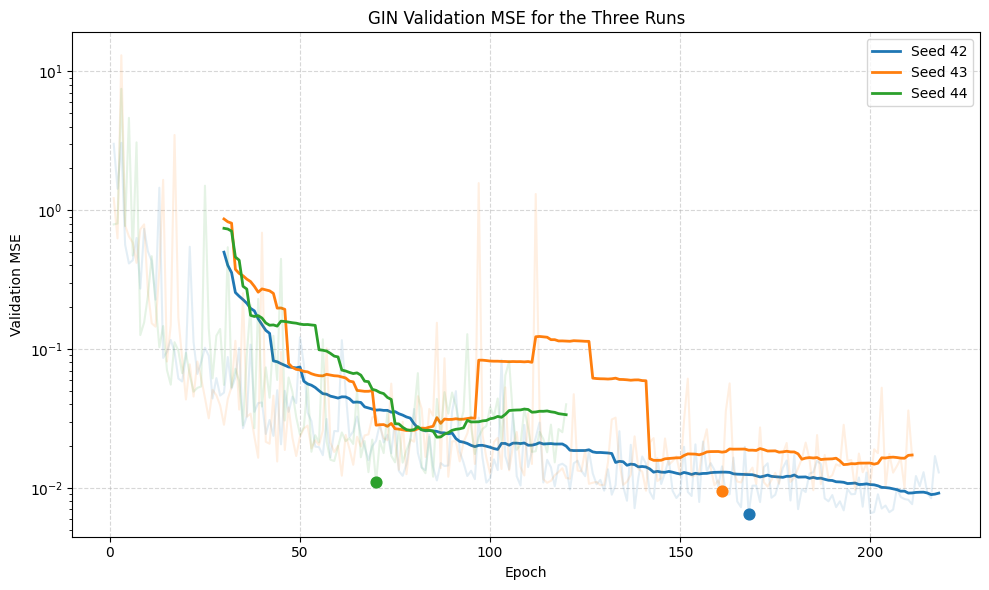

In [ ]:
window = 30

gin_runs[0]["color"] = "tab:blue"
gin_runs[1]["color"] = "tab:orange"
gin_runs[2]["color"] = "tab:green"

plt.figure(figsize=(10, 6))

for run in gin_runs:

    seed = run["seed"]
    val_loss = run["val_loss"]
    color = run["color"]

    best_epoch = min(
        range(len(val_loss)),
        key=lambda i: val_loss[i]
    ) + 1

    best_val_loss = val_loss[best_epoch - 1]

    val_loss_smooth = moving_average(
        val_loss,
        window=window
    )

    smooth_epochs = range(
        window,
        len(val_loss) + 1
    )

    plt.plot(
        range(1, len(val_loss) + 1),
        val_loss,
        color=color,
        alpha=0.12
    )

    plt.plot(
        smooth_epochs,
        val_loss_smooth,
        color=color,
        linewidth=2,
        label=f"Seed {seed}"
    )

    plt.scatter(
        best_epoch,
        best_val_loss,
        color=color,
        s=60,
        zorder=3
    )

    print(
        f"Seed {seed}: "
        f"best epoch = {best_epoch}, "
        f"best validation MSE = {best_val_loss:.4f}, "
        f"early stopping = {len(val_loss)}"
    )

plt.title("GIN Validation MSE for the Three Runs")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.yscale("log")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 6.3. GCN validation by seed

This plot uses the same conventions as the GIN figure: original values, 30-epoch moving average, actual minimum, and logarithmic scale. The best checkpoints occur at epochs **433, 341, and 367** for seeds 42, 43, and 44. The cell shows only the width-64 GCN.

Seed 42: best epoch = 433, best validation MSE = 11.7648, early stopping = 483
Seed 43: best epoch = 341, best validation MSE = 9.8226, early stopping = 391
Seed 44: best epoch = 367, best validation MSE = 10.3566, early stopping = 417


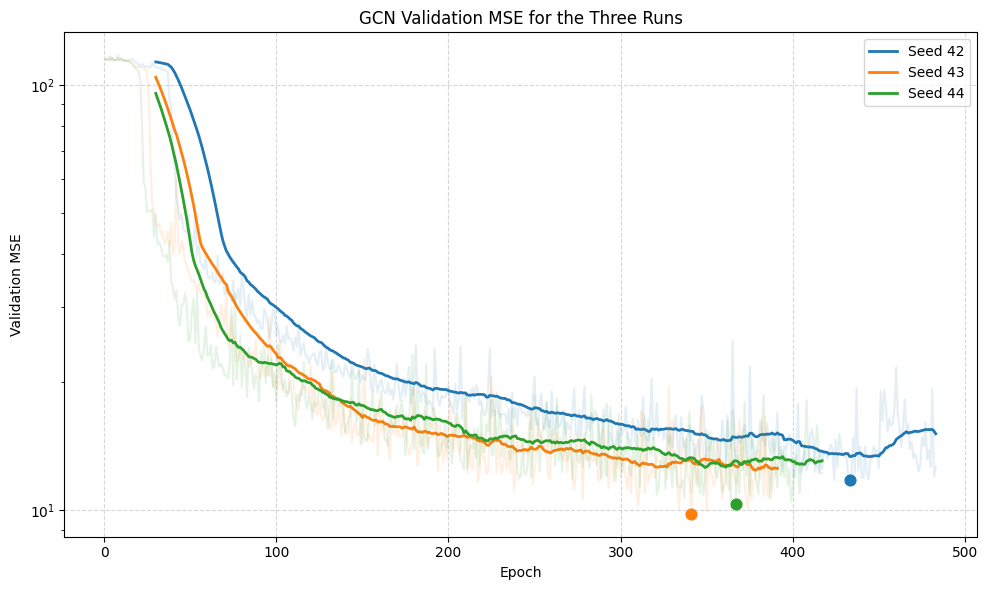

In [ ]:
window = 30

gcn_runs[0]["color"] = "tab:blue"
gcn_runs[1]["color"] = "tab:orange"
gcn_runs[2]["color"] = "tab:green"

plt.figure(figsize=(10, 6))

for run in gcn_runs:

    seed = run['seed']
    val_loss = run['val_loss']
    color = run["color"]

    best_epoch = min(
        range(len(val_loss)),
        key=lambda i: val_loss[i]
    ) + 1

    best_val_loss = val_loss[best_epoch - 1]

    val_loss_smooth = moving_average(
        val_loss,
        window=window
    )

    smooth_epochs = range(
        window,
        len(val_loss) + 1
    )

    plt.plot(
        range(1, len(val_loss) + 1),
        val_loss,
        color=color,
        alpha=0.12
    )


    plt.plot(
        smooth_epochs,
        val_loss_smooth,
        color=color,
        linewidth=2,
        label=f'Seed {seed}'
    )


    plt.scatter(
        best_epoch,
        best_val_loss,
        color=color,
        s=60,
        zorder=3
    )

    print(
        f"Seed {seed}: "
        f"best epoch = {best_epoch}, "
        f"best validation MSE = {best_val_loss:.4f}, "
        f"early stopping = {len(val_loss)}"
    )


plt.title('GCN Validation MSE for the Three Runs')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 6.4. Aggregating histories over common epochs

Early stopping produces different numbers of epochs across runs. This cell truncates the histories, **separately for each architecture**, to the length of the shortest run: **120 epochs for GIN** and **391 for GCN** in the saved outputs. Each point in the mean and sample standard deviation is therefore always based on three seeds.

This truncation is only a plotting convention: it does not change the checkpoints or test results. In particular, the mean GIN curve ends before the minima for seeds 42 and 43; the mean GCN curve ends before the minimum for seed 42.

In [ ]:
gin_common_epochs = min(
    len(run['train_loss']) for run in gin_runs
)

gcn_common_epochs = min(
    len(run['train_loss']) for run in gcn_runs
)


gin_train_curves = torch.tensor(
    [
        run['train_loss'][:gin_common_epochs]
        for run in gin_runs
    ],
    dtype=torch.float
)

gin_val_curves = torch.tensor(
    [
        run['val_loss'][:gin_common_epochs]
        for run in gin_runs
    ],
    dtype=torch.float
)


gcn_train_curves = torch.tensor(
    [
        run['train_loss'][:gcn_common_epochs]
        for run in gcn_runs
    ],
    dtype=torch.float
)

gcn_val_curves = torch.tensor(
    [
        run['val_loss'][:gcn_common_epochs]
        for run in gcn_runs
    ],
    dtype=torch.float
)


gin_train_mean = gin_train_curves.mean(dim=0)
gin_train_std = gin_train_curves.std(dim=0)

gin_val_mean = gin_val_curves.mean(dim=0)
gin_val_std = gin_val_curves.std(dim=0)

gcn_train_mean = gcn_train_curves.mean(dim=0)
gcn_train_std = gcn_train_curves.std(dim=0)

gcn_val_mean = gcn_val_curves.mean(dim=0)
gcn_val_std = gcn_val_curves.std(dim=0)


gin_epochs = range(1, gin_common_epochs + 1)
gcn_epochs = range(1, gcn_common_epochs + 1)

print(f"GIN: curve mediate sulle prime {gin_common_epochs} epoche.")
print(f"GCN: curve mediate sulle prime {gcn_common_epochs} epoche.")

GIN: curve mediate sulle prime 120 epoche.
GCN: curve mediate sulle prime 391 epoche.


### 6.5. Averaged training and validation: original two-panel figure

This figure shows the mean ± one standard deviation across the three seeds, over the common epochs computed above, without a moving average. The lower bands are clipped at zero for visualization only. **The two panels have the same vertical logarithmic scale**.

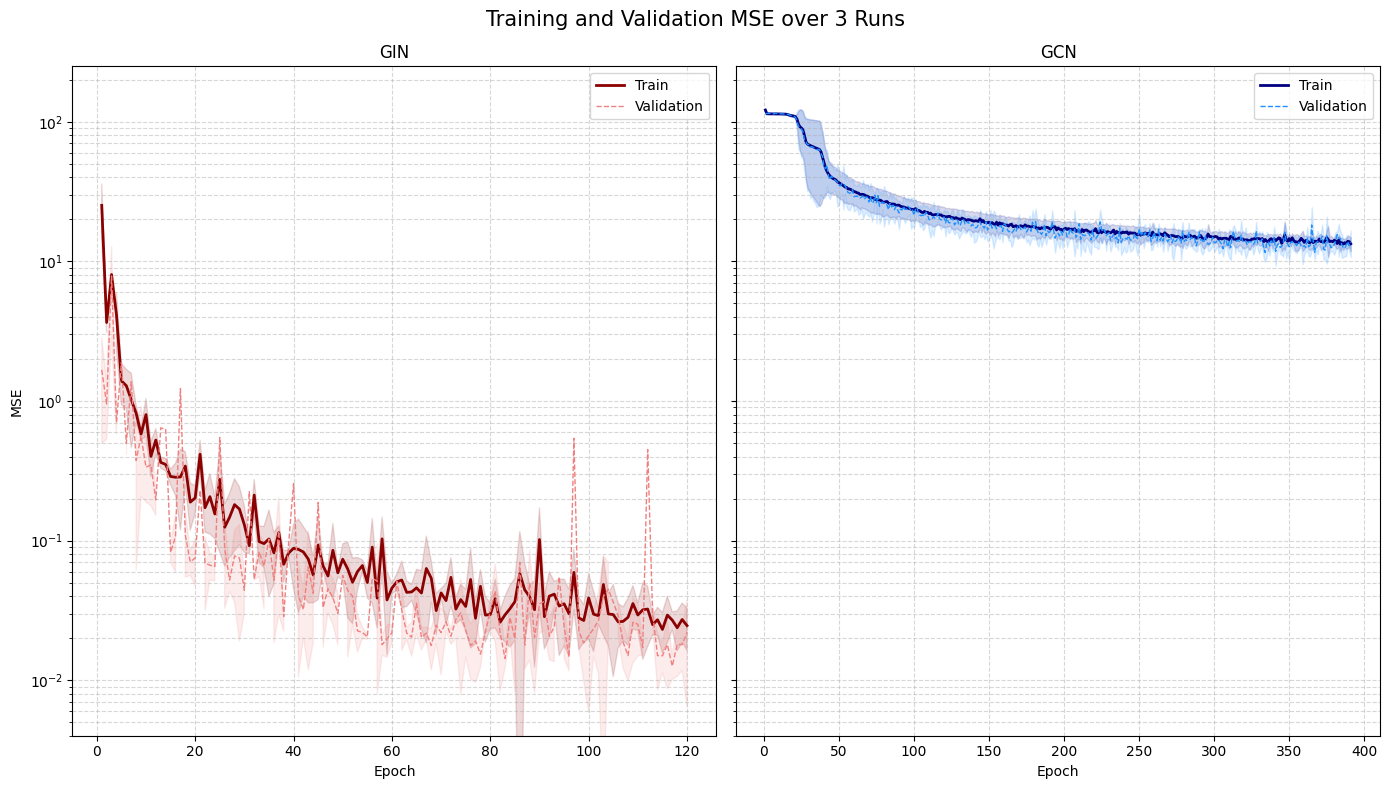

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), sharey=True)

gin_train_lower = gin_train_mean - gin_train_std
gin_train_upper = gin_train_mean + gin_train_std

gin_val_lower = gin_val_mean - gin_val_std
gin_val_upper = gin_val_mean + gin_val_std

ax1.plot(
    gin_epochs,
    gin_train_mean,
    label="Train",
    color="darkred",
    linewidth=2
)

ax1.fill_between(
    gin_epochs,
    gin_train_lower,
    gin_train_upper,
    where=gin_train_lower > 0,
    color="darkred",
    alpha=0.15,
    interpolate=True
)

ax1.plot(
    gin_epochs,
    gin_val_mean,
    label="Validation",
    color="lightcoral",
    linestyle="dashed",
    linewidth=1
)

ax1.fill_between(
    gin_epochs,
    gin_val_lower,
    gin_val_upper,
    where=gin_val_lower > 0,
    color="lightcoral",
    alpha=0.15,
    interpolate=True
)

ax1.set_title("GIN")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE")
ax1.set_yscale("log")
ax1.legend()
ax1.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.5
)

gcn_train_lower = gcn_train_mean - gcn_train_std
gcn_train_upper = gcn_train_mean + gcn_train_std

gcn_val_lower = gcn_val_mean - gcn_val_std
gcn_val_upper = gcn_val_mean + gcn_val_std

ax2.plot(
    gcn_epochs,
    gcn_train_mean,
    label="Train",
    color="navy",
    linewidth=2
)

ax2.fill_between(
    gcn_epochs,
    gcn_train_lower,
    gcn_train_upper,
    where=gcn_train_lower > 0,
    color="navy",
    alpha=0.15,
    interpolate=True
)

ax2.plot(
    gcn_epochs,
    gcn_val_mean,
    label="Validation",
    color="dodgerblue",
    linestyle="dashed",
    linewidth=1
)

ax2.fill_between(
    gcn_epochs,
    gcn_val_lower,
    gcn_val_upper,
    where=gcn_val_lower > 0,
    color="dodgerblue",
    alpha=0.15,
    interpolate=True
)

ax2.set_title("GCN")
ax2.set_xlabel("Epoch")
#ax2.set_ylabel("MSE")
#ax2.set_yscale("log")
ax2.legend()
ax2.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.5
)

ax1.set_ylim(0.004, 250)

fig.suptitle(
    "Training and Validation MSE over 3 Runs",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig("gin_vs_gcn.pdf", bbox_inches = "tight")

plt.tight_layout()
plt.show()

## 7. Documented results and interpretation

The following table transcribes the saved outputs, rounded to four decimal places. It does not replace the full-precision histories.

| Model | Width | Parameters | Test MSE, mean ± sample standard deviation |
|:--|--:|--:|--:|
| Constant baseline | — | — | 113.7849 |
| GCN | 64 | 8,513 | 11.4257 ± 0.8455 |
| GCN, parameter-matched control | 101 | 20,908 | 12.7500 ± 0.3478 |
| GIN, ε = 0 | 64 | 20,993 | 0.0089 ± 0.0026 |

### 7.1. Individual run details

| Model | Seed | Best epoch | Minimum validation MSE | Stopping epoch | Test MSE |
|:--|--:|--:|--:|--:|--:|
| GIN | 42 | 168 | 0.0065 | 218 | 0.0063 |
| GIN | 43 | 161 | 0.0095 | 211 | 0.0090 |
| GIN | 44 | 70 | 0.0110 | 120 | 0.0114 |
| GCN | 42 | 433 | 11.7648 | 483 | 12.2847 |
| GCN | 43 | 341 | 9.8226 | 391 | 10.5943 |
| GCN | 44 | 367 | 10.3566 | 417 | 11.3982 |
| GCNpm | 42 | 246 | 11.6458 | 296 | 13.1378 |
| GCNpm | 43 | 370 | 11.4199 | 420 | 12.4657 |
| GCNpm | 44 | 401 | 12.0235 | 451 | 12.6465 |

### 7.2. What the results support

In this comparison, GIN achieves an error more than three orders of magnitude lower than either GCN. Increasing the GCN width until its number of parameters is almost equal **does not close the gap**; the result therefore cannot be attributed solely to parameter count. All models improve on the constant baseline.

The result is consistent with the representational limitation discussed in the thesis for GCNs with constant features on regular graphs. However, it does not demonstrate that this limitation entirely causes the observed numerical gap: optimization, data, and protocol also matter.
